In [3]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Impostiamo un seed per rendere i dati riproducibili
np.random.seed(42)

# Generiamo i dati casuali ma realistici
n_ordini = 10000
prodotti = ['Smartphone Alpha', 'Laptop Pro 15', 'Cuffie Wireless', 'Smartwatch Fit', 'Monitor 4K', 'Tastiera Meccanica']
prezzi_base = [699, 1299, 99, 149, 349, 89]
categorie = ['Elettronica', 'Elettronica', 'Accessori', 'Accessori', 'Elettronica', 'Accessori']

data_inizio = datetime(2025, 1, 1)
date = [data_inizio + timedelta(days=int(np.random.randint(0, 365)), hours=int(np.random.randint(0, 24))) for _ in range(n_ordini)]
lista_prodotti = np.random.choice(prodotti, size=n_ordini, p=[0.25, 0.15, 0.25, 0.15, 0.10, 0.10])

df = pd.DataFrame({
    'ID_Ordine': [f'ORD-{i+10000}' for i in range(n_ordini)],
    'Data': date,
    'Cliente_ID': [f'USR-{np.random.randint(1000, 2500)}' for _ in range(n_ordini)],
    'Prodotto': lista_prodotti
})

# Associare prezzo e categoria
mappa_prezzi = dict(zip(prodotti, prezzi_base))
mappa_cat = dict(zip(prodotti, categorie))
df['Prezzo_Unitario'] = df['Prodotto'].map(mappa_prezzi)
df['Categoria'] = df['Prodotto'].map(mappa_cat)

# Generare quantità e calcolare il totale
df['Quantità'] = np.random.choice([1, 2, 3], size=n_ordini, p=[0.7, 0.2, 0.1])
df['Totale_Ordine'] = df['Prezzo_Unitario'] * df['Quantità']

# Introduciamo volutamente qualche valore mancante (NaN) per simulare dati reali da pulire
df.loc[df.sample(frac=0.02).index, 'Quantità'] = np.nan
df['Totale_Ordine'] = df['Prezzo_Unitario'] * df['Quantità']

# Mostra le prime 5 righe
print("Dataset generato con successo! Ecco un'anteprima:")
df.head()


Dataset generato con successo! Ecco un'anteprima:


,ID_Ordine,Data,Cliente_ID,Prodotto,Prezzo_Unitario,Categoria,Quantità,Totale_Ordine
0,ORD-10000,2025-04-13 19:00:00,USR-2262,Smartphone Alpha,699,Elettronica,1.0,699.0
1,ORD-10001,2025-12-15 14:00:00,USR-1728,Smartphone Alpha,699,Elettronica,1.0,699.0
2,ORD-10002,2025-04-17 07:00:00,USR-2200,Smartphone Alpha,699,Elettronica,3.0,2097.0
3,ORD-10003,2025-07-08 20:00:00,USR-1043,Cuffie Wireless,99,Accessori,1.0,99.0
4,ORD-10004,2025-04-13 18:00:00,USR-1303,Cuffie Wireless,99,Accessori,1.0,99.0


In [4]:
# 1. Contiamo i valori mancanti nel dataset grezzo
print("--- Controllo Valori Mancanti ---")
print(df.isnull().sum())
print("\n")

# 2. Eliminiamo le righe dove la quantità è vuota
df_pulito = df.dropna(subset=['Quantità']).copy()

# 3. Verifichiamo quante righe sono rimaste
print(f"Righe originarie nel database: {len(df)}")
print(f"Righe totali dopo la pulizia: {len(df_pulito)}")


--- Controllo Valori Mancanti ---
ID_Ordine            0
Data                 0
Cliente_ID           0
Prodotto             0
Prezzo_Unitario      0
Categoria            0
Quantità           200
Totale_Ordine      200
dtype: int64


Righe originarie nel database: 10000
Righe totali dopo la pulizia: 9800


In [5]:
# 1. Calcolo del fatturato totale dell'e-commerce
fatturato_totale = df_pulito['Totale_Ordine'].sum()
print(f"💰 FATTURATO TOTALE: € {fatturato_totale:,.2f}\n".replace(",", "."))

# 2. Classifica dei prodotti che hanno incassato di più
print("🏆 CLASSIFICA INCASSI PER PRODOTTO:")
classifica_prodotti = df_pulito.groupby('Prodotto')['Totale_Ordine'].sum().sort_values(ascending=False).to_frame()
classifica_prodotti['Totale_Ordine'] = classifica_prodotti['Totale_Ordine'].apply(lambda x: f"€ {x:,.2f}".replace(",", "."))
print(classifica_prodotti)


💰 FATTURATO TOTALE: € 6.384.039.00

🏆 CLASSIFICA INCASSI PER PRODOTTO:
                     Totale_Ordine
Prodotto                          
Laptop Pro 15       € 2.747.385.00
Smartphone Alpha    € 2.410.152.00
Monitor 4K            € 466.613.00
Cuffie Wireless       € 326.997.00
Smartwatch Fit        € 304.109.00
Tastiera Meccanica    € 128.783.00


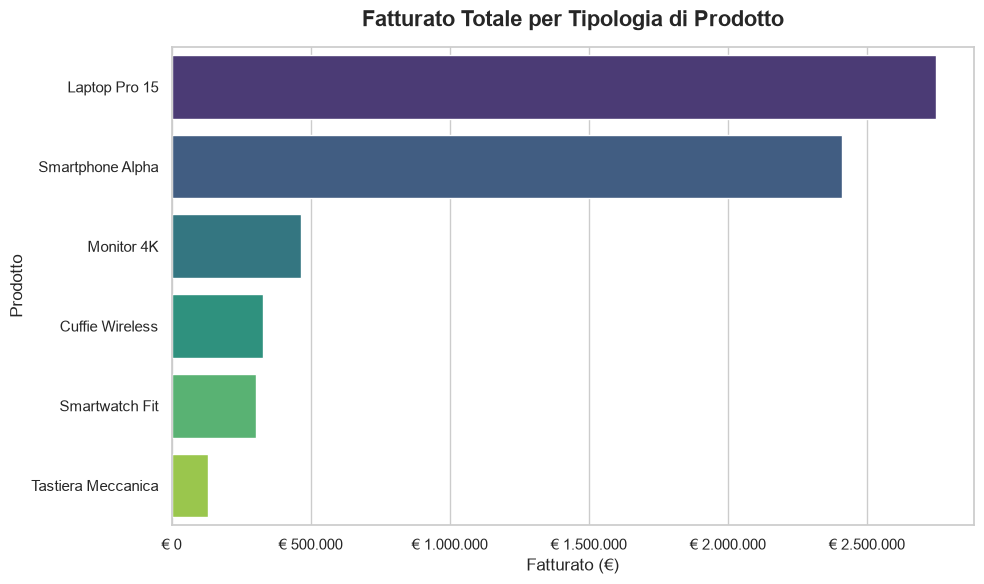

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FixedLocator

# Impostiamo lo stile del grafico
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# Calcoliamo i dati per il grafico
dati_grafico = df_pulito.groupby('Prodotto')['Totale_Ordine'].sum().sort_values(ascending=False).reset_index()

# Creiamo il grafico assegnando 'hue' per evitare il FutureWarning
ax = sns.barplot(
    x='Totale_Ordine', 
    y='Prodotto', 
    data=dati_grafico, 
    hue='Prodotto',
    palette='viridis',
    legend=False
)

# Configurazione titoli
plt.title('Fatturato Totale per Tipologia di Prodotto', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Fatturato (€)', fontsize=12)
plt.ylabel('Prodotto', fontsize=12)

# Risoluzione dello UserWarning usando il FixedLocator corretto
ticks = ax.get_xticks()
ax.xaxis.set_major_locator(FixedLocator(ticks))
labels = [f'€ {x:,.0f}'.replace(',', '.') for x in ticks]
ax.set_xticklabels(labels)

plt.tight_layout()
plt.show()


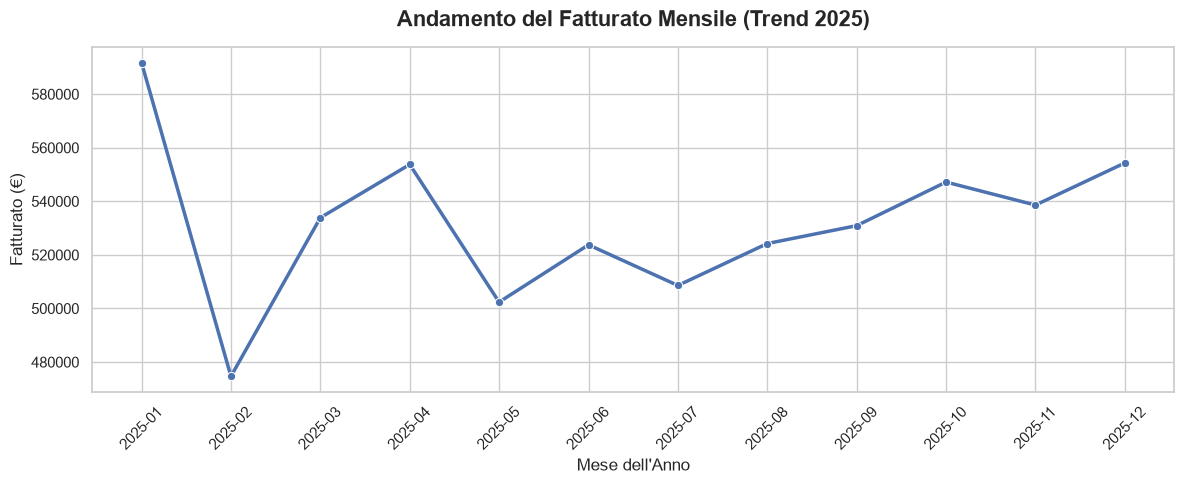

In [7]:
# 1. Estraiamo il mese dalla colonna 'Data' e creiamo una nuova colonna 'Mese'
df_pulito['Mese'] = df_pulito['Data'].dt.to_period('M')

# 2. Raggruppiamo i dati per mese e calcoliamo il totale delle vendite
andamento_mensile = df_pulito.groupby('Mese')['Totale_Ordine'].sum().reset_index()

# Convertiamo la colonna Mese in stringa per poterla plottare facilmente nel grafico
andamento_mensile['Mese'] = andamento_mensile['Mese'].astype(str)

# 3. Creiamo un grafico a linee per mostrare il trend temporale
plt.figure(figsize=(12, 5))
sns.lineplot(x='Mese', y='Totale_Ordine', data=andamento_mensile, marker='o', color='b', linewidth=2.5)

# Personalizziamo il grafico
plt.title('Andamento del Fatturato Mensile (Trend 2025)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Mese dell\'Anno', fontsize=12)
plt.ylabel('Fatturato (€)', fontsize=12)
plt.xticks(rotation=45) # Ruota i mesi per leggerli meglio

# Mostra il grafico
plt.tight_layout()
plt.show()


In [8]:
# 1. Creiamo una copia per non rovinare il dataset originale
df_json = df_pulito.copy()

# 2. Convertiamo la colonna Mese in testo normale (stringa) così JSON può leggerla
if 'Mese' in df_json.columns:
    df_json['Mese'] = df_json['Mese'].astype(str)

# 3. Convertiamo la colonna Data in testo leggibile
df_json['Data'] = df_json['Data'].dt.strftime('%Y-%m-%d %H:%M:%S')

# 4. Esportiamo finalmente in JSON senza errori
df_json.to_json('dati_vendite_puliti.json', orient='records', indent=4)

print("🎉 File 'dati_vendite_puliti.json' creato con successo nella tua cartella!")


🎉 File 'dati_vendite_puliti.json' creato con successo nella tua cartella!


In [9]:
%pip install pandas numpy matplotlib seaborn openpyxl


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
